# EDA — `NOM_DU_DATASET`

**Projet :** Compagnon Immobilier · **Auteur :** _ · **Relecteur :** _ · **Date :** _
**Fiche de description associée :** `description_<dataset>.ipynb`

# 0. Préparation des données suite à la première inspection

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


ventes = pd.read_csv("data/ech_annonces_ventes_68.csv", sep=";", encoding="utf-8-sig", index_col='idannonce')
location = pd.read_csv("data/ech_annonces_locations_68.csv", sep=";", encoding="utf-8-sig",index_col="idannonce")

sns.set_theme(style="whitegrid")          # fond blanc avec une grille légère
couleurs = {"Appartement": "#2a78d6", "Maison": "#eb6834"}   # bleu / orange



# ── Préparation : on retire les valeurs aberrantes repérées dans les premieres inspections ─────
v = ventes[(ventes["surface"] >= 9)
           & (ventes["prix_bien"] >= 20000)
           & (ventes["prix_m2_vente"] >= 500)
           & (ventes["prix_m2_vente"] <= 8000)
           & (ventes["typedebien_lite"] != "l")
           & (ventes["typedetransaction"] == "v")].copy()

# Libellés lisibles pour les graphiques
v["type"] = v["typedebien_lite"].replace({"a": "Appartement", "m": "Maison"})
v["neuf"] = v["logement_neuf"].replace({"o": "Neuf", "n": "Ancien"})
v["annee"] = pd.to_datetime(v["date"]).dt.year

# Location : Haut-Rhin uniquement, sans loyers ni surfaces aberrants
l = location[(location["DEP"] == 68)
             & (location["prix_bien"] >= 150)
             & (location["surface"] >= 9)
             & (location["typedebien_lite"] != "l")].copy()
l["loyer_m2"] = l["prix_bien"] / l["surface"]      # loyer au m² (absent du fichier)

print("Ventes conservées :", len(v), "| Locations conservées :", len(l))

Ventes conservées : 27280 | Locations conservées : 11669


# 1. Distribution du prix des annonces

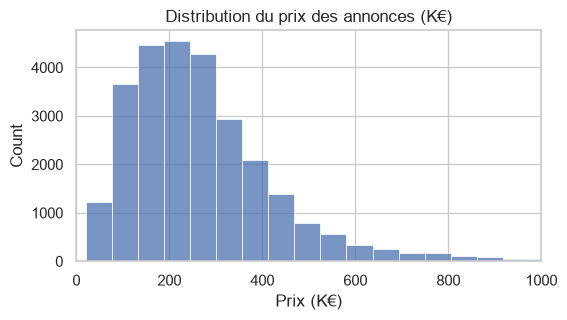

Moyenne : 274340 € | Médiane : 241000.0 €


In [18]:

plt.figure(figsize=(6, 3))  


sns.histplot(v["prix_bien"]/1000, bins=60) # on divise les valeurs par 1000 pour afficher en K€
plt.title("Distribution du prix des annonces (K€)")

plt.xlim(0, 1000)


plt.xlabel("Prix (K€)")   


plt.show()

# Validation : si la moyenne dépasse nettement la médiane, la distribution est asymétrique
print("Moyenne :", round(v["prix_bien"].mean()), "€ | Médiane :", v["prix_bien"].median(), "€")

**Interpretation du graphique**

La grande majorité des annonces se situe entre 100 et 400k euros. Le prix median des annonces est inférieur à la moyenne car les logements tres chers tirent cette-dernière vers le haut et on ne peut pas dire que ca suit une loi normale.

# 2. Prix au prix au m² selon le type de bien et le neuf

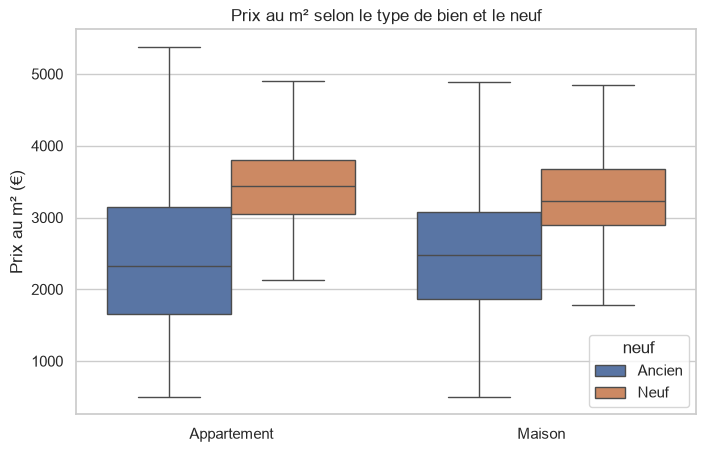

Appartement : neuf 3503 €/m² | ancien 2453 €/m²
TtestResult(statistic=np.float64(47.901846111229574), pvalue=np.float64(0.0), df=np.float64(1798.4429265795654))
Maison : neuf 3339 €/m² | ancien 2528 €/m²
TtestResult(statistic=np.float64(49.33653236663681), pvalue=np.float64(0.0), df=np.float64(4725.310919903021))


In [19]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=v, x="type", y="prix_m2_vente", hue="neuf",
            showfliers=False)                        # showfliers=False : on masque les points extrêmes
plt.title("Prix au m² selon le type de bien et le neuf")
plt.xlabel("")
plt.ylabel("Prix au m² (€)")
plt.show()

# Validation : test t (compare deux moyennes), pour les appartements puis les maisons
for t in ["Appartement", "Maison"]:
    groupe = v[v["type"] == t]
    neuf = groupe[groupe["neuf"] == "Neuf"]["prix_m2_vente"]
    ancien = groupe[groupe["neuf"] == "Ancien"]["prix_m2_vente"]
    print(t, ": neuf", round(neuf.mean()), "€/m² | ancien", round(ancien.mean()), "€/m²")
    print(stats.ttest_ind(neuf, ancien, equal_var=False))

**Interpretation du graphique**

On remarque que la médiane du neuf est toujours supérieure à celle de l'ancien que ce soit pour les appartements ou les maisons. On remarque également une plus grande dispersion pour l'ancien qui peut s'expliquer par une proportion plus grande d'appartement anciens que neuf.

**Choix et interpretation du test**

Nous voulons comparer deux moyennes de deux groupes différents avec une variable quantitative et une variable qualitative à deux modalités. Plus précisément ici on utilise la version de Welch du test t de Student, qui ne suppose pas l’égalité des variances, car les groupes sont de tailles très différentes avec le paramètre equal_var=False. En effet les groupes sont très déséquilibrés (environ 1 200 appartements neufs contre 12 400 anciens) et leurs dispersions de prix diffèrent. 

**Constat :** le neuf est nettement plus cher au m² que l'ancien. Pour les appartements, le prix moyen passe de 2 453 €/m² dans l'ancien à 3 503 €/m² dans le neuf (+43 %). Pour les maisons, il passe de 2 528 à 3 339 €/m² (+32 %).

**Validation :** statistic (environ 48 et 49) : l’écart entre les deux moyennes, rapporté à leur variabilité. Au-delà d’environ 2, la différence est déjà significative ; ici, elle est énorme.
pvalue = 0.0 : la probabilité d’observer un tel écart si, en réalité, neuf et ancien avaient le même prix moyen est très faible p < 0,001. Comme la p-value est inférieure à 0,05, on rejette l’hypothèse d’égalité des moyennes : le prix au m² moyen du neuf est significativement supérieur à celui de l’ancien, pour les appartements comme pour les maisons.

**Avis métier :** la prime du neuf s'explique par la performance énergétique (DPE A ou B), les normes de construction récentes, l'absence de travaux à prévoir et des frais de notaire réduits (environ 2 à 3 % contre 7 à 8 % dans l'ancien). L'écart est plus fort pour les appartements, souvent vendus dans des programmes neufs en ville. 

# 3. Prix en fonction de la surface

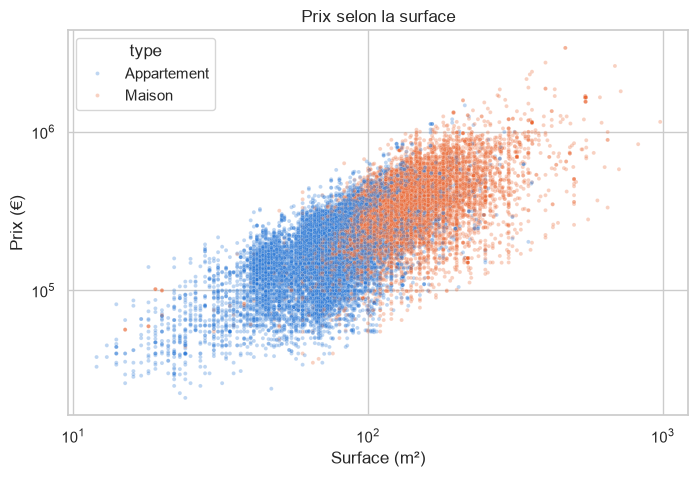

Pearson surface / prix : PearsonRResult(statistic=np.float64(0.7123045234298147), pvalue=np.float64(0.0))
Appartement | Pearson surface / prix au m² : PearsonRResult(statistic=np.float64(-0.1470985649171021), pvalue=np.float64(6.683054830070406e-67))
Appartement | Spearman surface / prix au m² : SignificanceResult(statistic=np.float64(-0.17976573619524966), pvalue=np.float64(1.6259931601106384e-99))
Maison | Pearson surface / prix au m² : PearsonRResult(statistic=np.float64(-0.18820526570136883), pvalue=np.float64(7.112472395012731e-109))
Maison | Spearman surface / prix au m² : SignificanceResult(statistic=np.float64(-0.205321770211206), pvalue=np.float64(1.2016269562321726e-129))


In [23]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=v, x="surface", y="prix_bien", hue="type",
                palette=couleurs, s=8, alpha=0.3)    # s = taille des points, alpha = transparence
plt.xscale("log")                                    # échelles log : les points sont mieux répartis
plt.yscale("log")
plt.title("Prix selon la surface")
plt.xlabel("Surface (m²)")
plt.ylabel("Prix (€)")
plt.show()

# Validation : corrélation entre surface et prix, puis entre surface et prix au m²
print("Pearson surface / prix :", stats.pearsonr(v["surface"], v["prix_bien"]))
for t in ["Appartement", "Maison"]:
    groupe = v[v["type"] == t]
    print(t, "| Pearson surface / prix au m² :", stats.pearsonr(groupe["surface"], groupe["prix_m2_vente"]))
    print(t, "| Spearman surface / prix au m² :", stats.spearmanr(groupe["surface"], groupe["prix_m2_vente"]))

**Interpretation du graphique**

Les nuages de points semblent montrer une relation linéaire entre le prix et la surface. Les appartements restent gloabalement moins chers et une séparation nette à partir de 100m2 laisse place aux maisons

**Choix et intéprétations des tests**

Corrélations de Pearson et de Spearman. On étudie le lien entre deux variables quantitatives (surface et prix). Pearson mesure une relation linéaire. Spearman, basé sur les rangs, mesure une relation monotone (qui monte ou descend régulièrement), même si elle n'est pas linéaire, et il est moins sensible aux valeurs extrêmes. Présenter les deux permet de vérifier si la relation est linéaire.

Résultat :
- Surface / prix : Pearson r = 0,71 (p < 0,001).
- Surface / prix au m² : Pearson -0,15 et Spearman -0,18 pour les appartements ; -0,19 et -0,21 pour les maisons (p < 0,001).

Conclusion :le prix augmente fortement avec la surface. Le prix au m², lui, diminue légèrement quand la surface augmente. Spearman est un peu plus fort que Pearson : la relation n'est pas tout à fait linéaire.

Avis métier : la surface est la variable la plus explicative du prix, ce qui confirme qu'elle sera centrale dans le modèle. La baisse du prix au m² avec la surface est bien connue : c'est la **dégressivité**. Les pièces « coûteuses » (cuisine, salle de bain) existent dans tous les logements, quelle que soit leur taille, donc les petites surfaces reviennent plus cher au m².

# 3. Prix au m² selon l'étiquette DPE

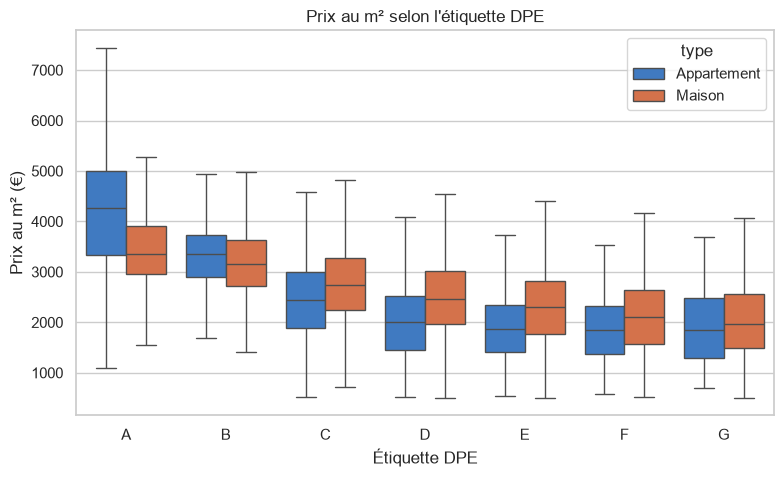

F_onewayResult(statistic=np.float64(923.8645451458675), pvalue=np.float64(0.0))
dpeL
A    3781.745
B    3282.610
C    2600.000
D    2225.490
E    2079.550
F    2002.015
G    1945.045
Name: prix_m2_vente, dtype: float64
F_onewayResult(statistic=np.float64(668.6496064878946), pvalue=np.float64(0.0))


In [28]:
ordre = ["A", "B", "C", "D", "E", "F", "G"]
d = v[v["dpeL"].isin(ordre)]           # on retire 0, NS et VI

plt.figure(figsize=(9, 5))
sns.boxplot(data=d, x="dpeL", y="prix_m2_vente", hue="type",
            order=ordre, palette=couleurs, showfliers=False)
plt.title("Prix au m² selon l'étiquette DPE")
plt.xlabel("Étiquette DPE")
plt.ylabel("Prix au m² (€)")
plt.show()

# Validation 1 : ANOVA (compare les moyennes des 7 classes)
print(stats.f_oneway(d[d["dpeL"] == "A"]["prix_m2_vente"], d[d["dpeL"] == "B"]["prix_m2_vente"],
                     d[d["dpeL"] == "C"]["prix_m2_vente"], d[d["dpeL"] == "D"]["prix_m2_vente"],
                     d[d["dpeL"] == "E"]["prix_m2_vente"], d[d["dpeL"] == "F"]["prix_m2_vente"],
                     d[d["dpeL"] == "G"]["prix_m2_vente"]))



# Validation 2 : même ANOVA sur les seuls logements anciens (sans l'effet du neuf)
anc = d[d["neuf"] == "Ancien"]
print(anc.groupby("dpeL")["prix_m2_vente"].median()) # on affiche pour visualiser la decote de prix en fonction de l'étiquette pour les logements anciens
print(stats.f_oneway(anc[anc["dpeL"] == "A"]["prix_m2_vente"], anc[anc["dpeL"] == "B"]["prix_m2_vente"],
                     anc[anc["dpeL"] == "C"]["prix_m2_vente"], anc[anc["dpeL"] == "D"]["prix_m2_vente"],
                     anc[anc["dpeL"] == "E"]["prix_m2_vente"], anc[anc["dpeL"] == "F"]["prix_m2_vente"],
                     anc[anc["dpeL"] == "G"]["prix_m2_vente"]))

**Interpretation du graphique**

La médiane du prix au m2 pour un appartement est plus cher pour les étiquettes A et B mais ca vient surement du fait qu'il y a plus de données pour les appartements en A et B car en général les logements neufs viennent de promoteur immobilier qui construisent des immeubles neufs. On constate également qu'a partir de l'étiquette D il n'y a plus trop d'effet sur le prix au m2


**Choix et intéprétations des tests**

- ANOVA, car on compare la moyenne d'une variable quantitative (prix au m²) entre **plus de deux groupes** (les 7 étiquettes). Le test t ne compare que deux groupes.


Résultat :
- ANOVA sur tous les biens : F = 924, p < 0,001.
- ANOVA sur les seuls logements anciens : F = 672, p < 0,001. Le prix médian passe de 3 782 €/m² en A à 1 941 €/m² en G.

Conclusion : le prix au m² diffère significativement selon l'étiquette DPE. Le DPE est fortement lié au neuf, mais l'écart reste très net quand on ne garde que l'ancien : l'effet du DPE ne s'explique pas uniquement par le neuf.

Avis métier : les logements économes se vendent plus cher, et les passoires thermiques (F, G) subissent une décote. Cette décote devrait s'accentuer avec l'interdiction progressive de louer les logements classés G puis F, qui réduit leur intérêt pour les investisseurs. Le DPE est donc une variable utile pour le modèle, mais il faudra tenir compte de son lien avec le neuf.

# 4. Evolution du prix au m² dans le temps

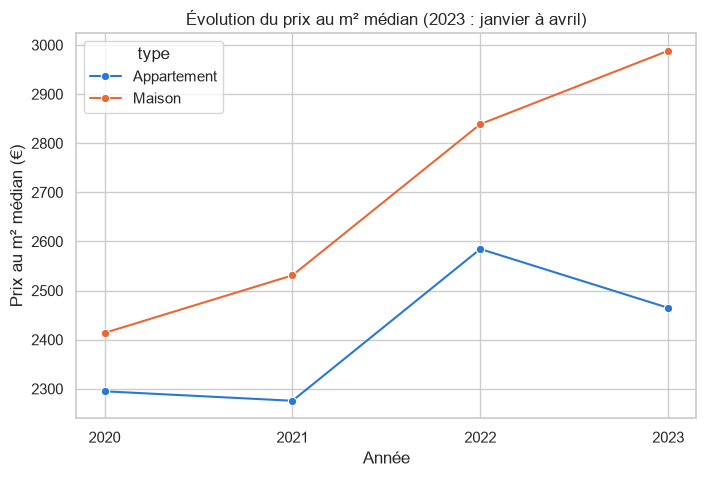

Maison annee
2020    2404.0
2021    2535.0
2022    2814.0
2023    2998.0
Name: prix_m2_vente, dtype: float64
F_onewayResult(statistic=np.float64(250.93791474785448), pvalue=np.float64(1.7928654203872843e-158))
Appartement annee
2020    2403.0
2021    2394.0
2022    2693.0
2023    2675.0
Name: prix_m2_vente, dtype: float64
F_onewayResult(statistic=np.float64(83.76137024100781), pvalue=np.float64(1.127116643750621e-53))
(np.float64(461.7126625563525), np.float64(1.2752289783553414e-98))


In [31]:
v2020 = v[v["annee"] >= 2020]                        # 2019 contient trop peu d'annonces

# Prix au m² médian par année et par type de bien
evolution = v2020.groupby(["annee", "type"])["prix_m2_vente"].median().reset_index()

plt.figure(figsize=(8, 5))
sns.lineplot(data=evolution, x="annee", y="prix_m2_vente", hue="type",
             palette=couleurs, marker="o")
plt.xticks([2020, 2021, 2022, 2023])                 # une graduation par année
plt.title("Évolution du prix au m² médian (2023 : janvier à avril)")
plt.xlabel("Année")
plt.ylabel("Prix au m² médian (€)")
plt.show()

# Validation 1 : ANOVA entre les années, pour les maisons puis les appartements
for t in ["Maison", "Appartement"]:
    groupe = v2020[v2020["type"] == t]
    print(t, groupe.groupby("annee")["prix_m2_vente"].mean().round())
    print(stats.f_oneway(groupe[groupe["annee"] == 2020]["prix_m2_vente"],
                         groupe[groupe["annee"] == 2021]["prix_m2_vente"],
                         groupe[groupe["annee"] == 2022]["prix_m2_vente"],
                         groupe[groupe["annee"] == 2023]["prix_m2_vente"]))

# Validation 2 : khi-deux, la part maisons / appartements change-t-elle selon l'année ?
print(stats.chi2_contingency(pd.crosstab(v["annee"], v["type"]))[:2])

**Interpretation du graphique**

Le prix médian a tendance à augmenter entre 2020 et 2023 pour les maisons. Pour les appartements aussi mais un pic en 2022.
Ca reste une très courte période d'analyse et on rappelle qu'on n'est que dans le 68.

**Choix et intéprétations des tests**

Tests choisis :
- **ANOVA**, car on compare la moyenne du prix au m² entre **quatre groupes** (les années 2020 à 2023).
- **Khi-deux**, car on vérifie si la composition du jeu (part de maisons et d'appartements, deux variables qualitatives) change selon l'année. Si c'est le cas, une évolution du prix moyen tous biens confondus pourrait venir du changement de composition, et non d'une vraie évolution du marché.

Résultat :
- Maisons : 2 404 €/m² en moyenne en 2020, puis 2 535, 2 814 et 2 998 € en 2023 (+25 %). ANOVA p < 0,001.
- Appartements : 2 403 €/m² en 2020, 2 394 en 2021, 2 693 en 2022 et 2 675 € en 2023. ANOVA p < 0,001.
- Khi-deux année × type de bien : p < 0,001.

Conclusion : le prix au m² a significativement évolué entre 2020 et 2023, pour les maisons comme pour les appartements. La composition du jeu change aussi selon l'année, ce qui justifie d'analyser les deux types de biens séparément.

Avis métier : les maisons ont connu une hausse continue, cohérente avec la recherche d'espace et de jardin après les confinements de 2020. Les appartements ont progressé jusqu'en 2022 puis se sont stabilisés en 2023, au moment de la forte remontée des taux de crédit, qui réduit la capacité d'emprunt des acheteurs. L'année 2023 ne couvre que janvier à avril : la tendance est à confirmer.